# DINOv2 embeddings of CIFAR-100

Can an isotropic Gaussian effective process predict the dynamics of a linear
head self-training on a fixed learned image representation, including
confidently wrong pseudo-labels?

[CIFAR-100](https://cave.cs.toronto.edu/kriz/cifar.html#cifar100)
groups 100 fine categories into 20 superclasses. We combine selected
superclasses into two binary labels and train linear classifiers on
768-dimensional features from a frozen
[DINOv2 ViT-B/14](https://github.com/facebookresearch/dinov2/blob/main/MODEL_CARD.md)
encoder. ST stands for self-training. The configured groups and their fine categories are shown below.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from importlib import reload
from pathlib import Path
import sys

cwd = Path.cwd()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "algorithms.py").is_file()
     and (path / "experiments" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import display
import torch

# Refresh edited local modules when this cell is rerun in an open kernel.
for module_name in ("experiments.plotting", "experiments.cifar_dinov2"):
    if module_name in sys.modules:
        reload(sys.modules[module_name])

from experiments.cifar_dinov2 import (
    CIFAR100Embeddings,
    DINOv2CIFAR100Experiment,
    describe_cifar_groups,
    save_dinov2_cifar100_figures,
    save_checkpoint_distributions,
)

CACHE_DIR = ROOT / "outputs" / "dinov2_cifar100_self_training" / "cache"
FIGURES_DIR = ROOT / "outputs" / "figures"

In [3]:
# Experiment configuration
experiment_config = {
    "class_proportions": [0.5, 0.2],
    "labeling_rate": 0.01,
    "n_train": 6000,
    "n_test": 500,
    "seeds": range(42, 52),
    "training_steps": 200,
    "checkpoint_times": [0, 20, 50, 100],
    "eta": 0.05,
    "reg_lambda": 0.1,
    "pi": 5.0,
    "tau": 0.8,
    # Aquatic mammals, large carnivores, and large omnivores/herbivores.
    "negative_superclasses": (0, 8, 11),
    # Medium and small mammals.
    "positive_superclasses": (12, 16),
    "pilot_holdout_per_class": 200,
    "pilot_seed": 2026,
    "whitening_ridge_fraction": 0.01,
    "sample_particles": 2000,  # preserves the default label and revelation counts exactly
    "particle_seed": 47,
}

encoder_batch_size = 32
encoder_device = "cuda" if torch.cuda.is_available() else (
    "mps" if torch.backends.mps.is_available() else "cpu"
)
torch.set_num_threads(4)

## Official splits and frozen embeddings

Use Meta's published evaluation transform with bicubic resize to 256,
center crop to 224, and ImageNet normalization. Extract the 768-dimensional
class token in float32. Cache features separately by official split and
coarse class. The cache records the source revision, weights digest, image
IDs, and input transform.

In [4]:
embeddings = CIFAR100Embeddings(
    CACHE_DIR, device=encoder_device, batch_size=encoder_batch_size,
)
experiment = DINOv2CIFAR100Experiment(
    embeddings, **experiment_config
)

print(f"Embedding cache: {CACHE_DIR}")
print(f"Encoder device: {encoder_device}")
display(describe_cifar_groups(
    embeddings, experiment.negative_superclasses, experiment.positive_superclasses,
))

Embedding cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/outputs/dinov2_cifar100_self_training/cache
Encoder device: cpu


| Binary label | Superclass (ID) | Fine categories |
| --- | --- | --- |
| -1 | aquatic mammals (0) | beaver, dolphin, otter, seal, whale |
| -1 | large carnivores (8) | bear, leopard, lion, tiger, wolf |
| -1 | large omnivores and herbivores (11) | camel, cattle, chimpanzee, elephant, kangaroo |
| +1 | medium mammals (12) | fox, porcupine, possum, raccoon, skunk |
| +1 | small mammals (16) | hamster, mouse, rabbit, shrew, squirrel |

### Training and test pools

Sample from the official splits. Exclude the original seeded holdout of
200 images per superclass to preserve the training pool used by these figures.

In [5]:
experiment.prepare_training_pool()

In [6]:
experiment.load_test_embeddings()

## Class-specific whitening (oracle)

Fit a whitening transform to the residuals of each class using the
training embeddings. Preserve the class means in the pooled-whitened
coordinates. The transform uses the true class of each input, including
test images, so this is an oracle comparison. Compare self-training on real embeddings, finite Gaussian self-training,
and the effective process for the fitted Gaussian.

The six-panel figures evaluate test error on the same held-out CIFAR rows and
selection on the same unlabeled CIFAR training rows for all three methods.
The selected-error fraction counts wrong pseudo-labels divided by the number of
unlabeled rows.

The three-panel diagnostic subtracts the DINOv2 value within each seed.
For native evaluation, solid lines show medians, dotted lines show means,
and shading shows interquartile ranges. Native test error uses the fitted
Gaussian population. Native selection uses the finite Gaussian training
rows or effective-process particles.
The gray zero line marks agreement with DINOv2.

In [7]:
class_whitened_runs = experiment.run_class_whitening()

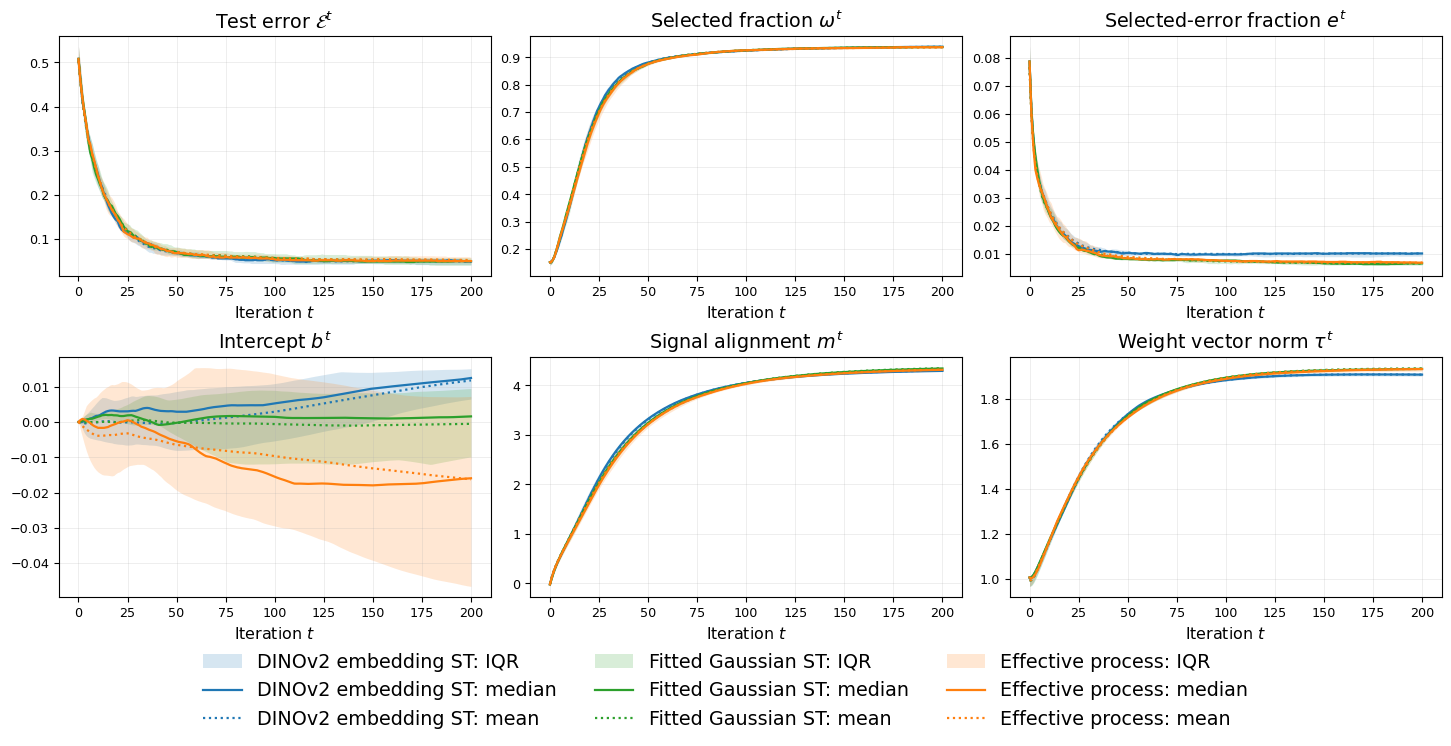

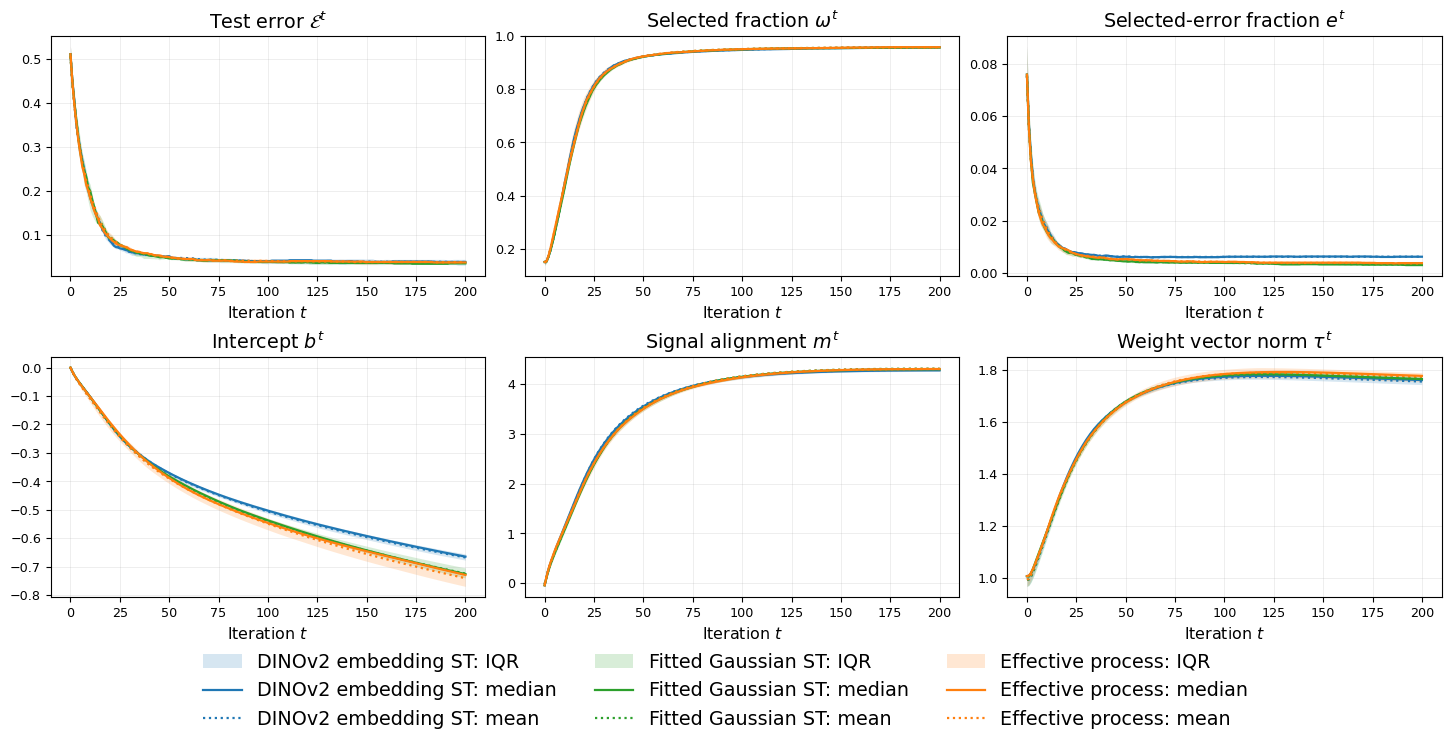

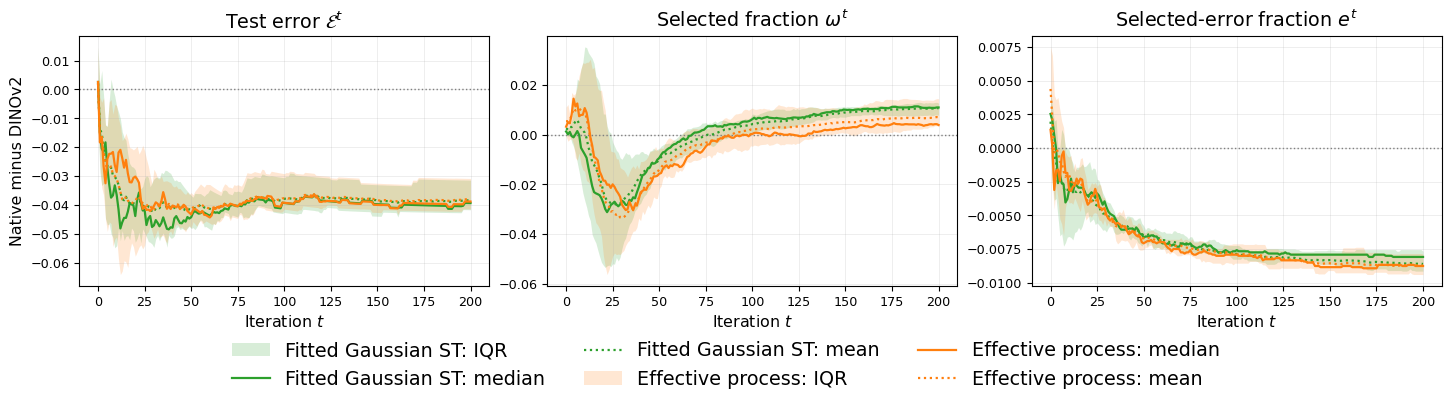

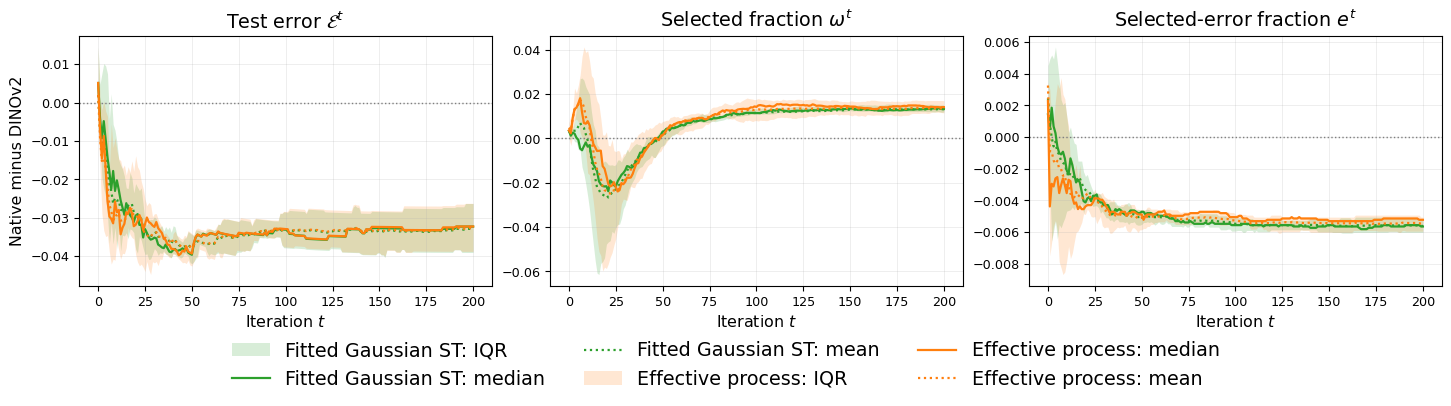

In [8]:
save_dinov2_cifar100_figures(
    FIGURES_DIR, class_whitened_runs, "dinov2_cifar100_mammal_groups_class_whitened"
)

## Overall training-score and weight distributions

At each checkpoint, compare the real self-training run with its effective
process, pooling seeds within each class proportion. Training-score densities appear
above the weight-coordinate densities. The score panels include labeled
and unlabeled training rows, and all sample-side effective particles. The dashed
lines mark the selection thresholds for unlabeled examples $\pm\log(\tau/(1-\tau))$. The weight
panels use the raw coordinates of $w^t$. Each panel shows the marginal
distribution at that iteration.

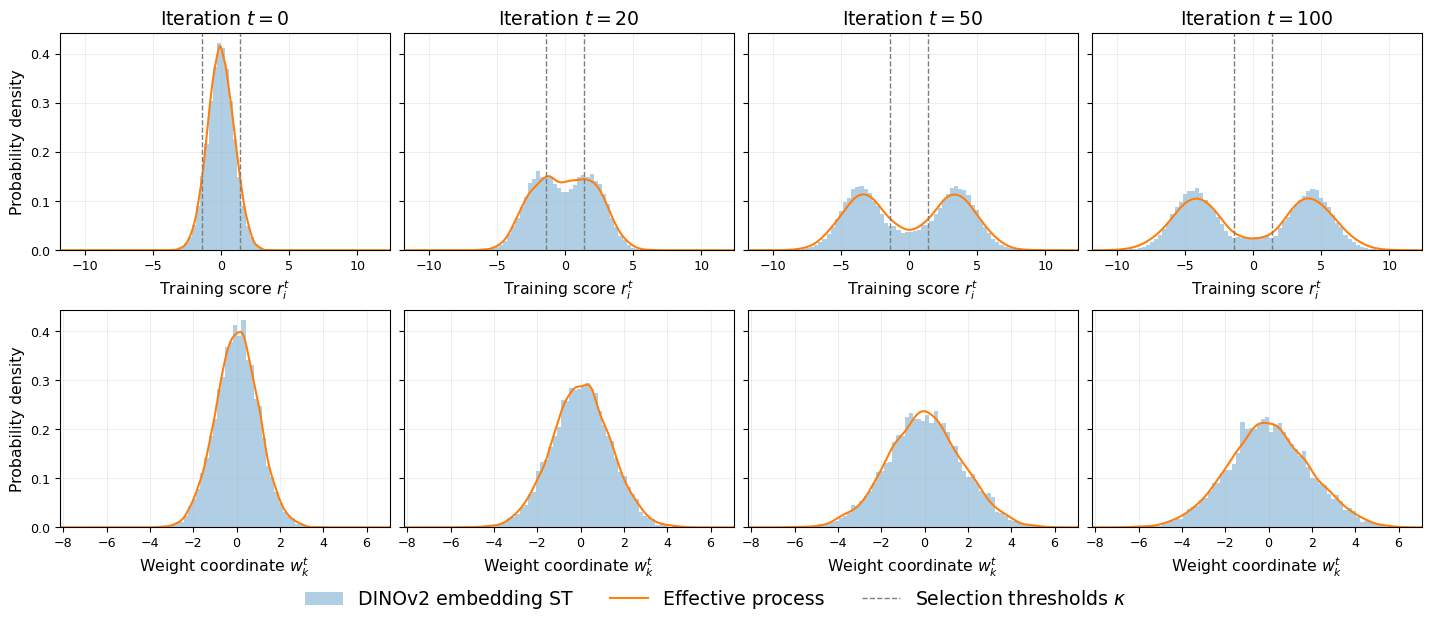

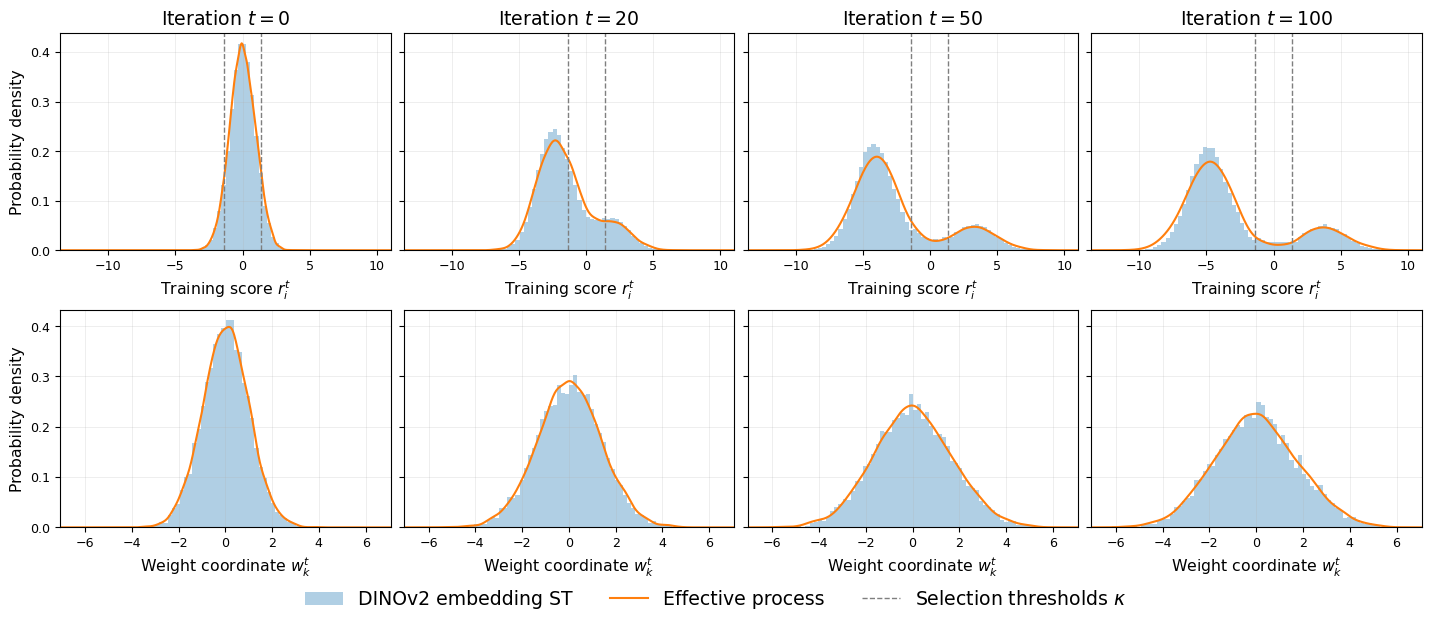

In [9]:
head_config = experiment.head_config(experiment.training_steps, experiment.pi)
save_checkpoint_distributions(
    FIGURES_DIR,
    class_whitened_runs,
    experiment.checkpoint_times,
    score_thresholds=(head_config.negative_margin, head_config.positive_margin),
)